# Agrupamiento

El agrupamiento (clustering) es la tarea no supervisada más común: dividir las observaciones en grupos de modo que las de un mismo grupo se parezcan entre sí y se diferencien de las de otros grupos. No hay una respuesta que predecir ni una verdad con que comparar, así que el resultado depende de cómo se define la similitud, del algoritmo y del número de grupos, y siempre debe interpretarse con conocimiento del problema {cite}`james2021,hastie2009`. En geociencias se usa para definir facies a partir de registros de pozo, agrupar muestras geoquímicas, regionalizar cuencas por su respuesta hidrológica o segmentar imágenes.

## Datos de ejemplo

Se simulan análisis geoquímicos de 600 muestras de roca con cinco óxidos, provenientes de tres litologías (basalto, andesita y granito) más un pequeño grupo de rocas alteradas. Para el algoritmo las litologías son desconocidas; se usan solo al final para evaluar el resultado. Como las variables tienen rangos muy distintos, se estandarizan: los métodos basados en distancias no son invariantes a la escala.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(6)

oxidos = ['SiO2', 'Al2O3', 'FeOt', 'MgO', 'K2O']
medias = {'basalto': [49, 15, 11, 8, 0.5], 'andesita': [58, 17, 7, 4, 1.5], 'granito': [72, 14, 2.5, 0.8, 4.2], 'alterada': [62, 20, 4, 1.0, 5.5]}
desv = {'basalto': [1.5, 1, 1.2, 1.2, 0.2], 'andesita': [2, 1, 1, 0.8, 0.4], 'granito': [2, 0.8, 0.7, 0.3, 0.5], 'alterada': [3, 1.5, 1.2, 0.4, 0.8]}
tam = {'basalto': 200, 'andesita': 200, 'granito': 170, 'alterada': 30}
X, lito = [], []
for k in medias:
    X.append(rng.normal(medias[k], desv[k], (tam[k], 5))); lito += [k] * tam[k]
X = np.vstack(X); lito = np.array(lito)
Xs = StandardScaler().fit_transform(X)
print('Muestras por litología:', {k: int((lito == k).sum()) for k in medias})

Muestras por litología: {'basalto': 200, 'andesita': 200, 'granito': 170, 'alterada': 30}


## k-medias

El algoritmo de k-medias busca $k$ grupos que minimicen la suma de las distancias cuadradas de cada punto al centroide de su grupo (la inercia). Parte de $k$ centroides iniciales, asigna cada punto al más cercano, recalcula los centroides y repite hasta que nada cambia. Es rápido y simple, pero exige fijar $k$, supone grupos más o menos esféricos y de tamaño parecido, y su resultado depende de la inicialización (por eso se corre varias veces). Para elegir $k$ se usan el método del codo, que busca el punto a partir del cual la inercia deja de bajar mucho, y el coeficiente de silueta {cite}`rousseeuw1987`, que compara la distancia media de cada punto a su grupo con la distancia al grupo vecino más cercano: vale cerca de 1 si el punto está bien agrupado, cerca de 0 si está en la frontera y es negativo si probablemente está en el grupo equivocado.

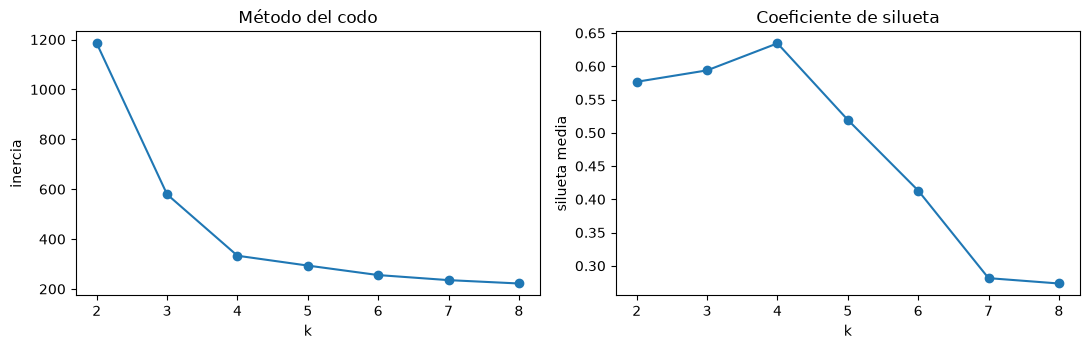

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    inercia.append(km.inertia_); silueta.append(silhouette_score(Xs, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(ks, inercia, 'o-'); ax[0].set_xlabel('k'); ax[0].set_ylabel('inercia'); ax[0].set_title('Método del codo')
ax[1].plot(ks, silueta, 'o-'); ax[1].set_xlabel('k'); ax[1].set_ylabel('silueta media'); ax[1].set_title('Coeficiente de silueta')
plt.tight_layout(); plt.show()

El codo aparece en k = 4 y la silueta media también es máxima con cuatro grupos: k-medias separa las tres litologías y además el pequeño grupo de rocas alteradas, que con k = 3 queda absorbido por el granito. La gráfica de silueta por muestra permite ver la calidad de cada grupo; el de las rocas alteradas, más disperso, tiene siluetas menores. El índice de Rand ajustado, que compara dos particiones (1 es coincidencia perfecta y 0 la esperada por azar), confirma que con cuatro grupos el resultado reproduce casi exactamente las litologías.

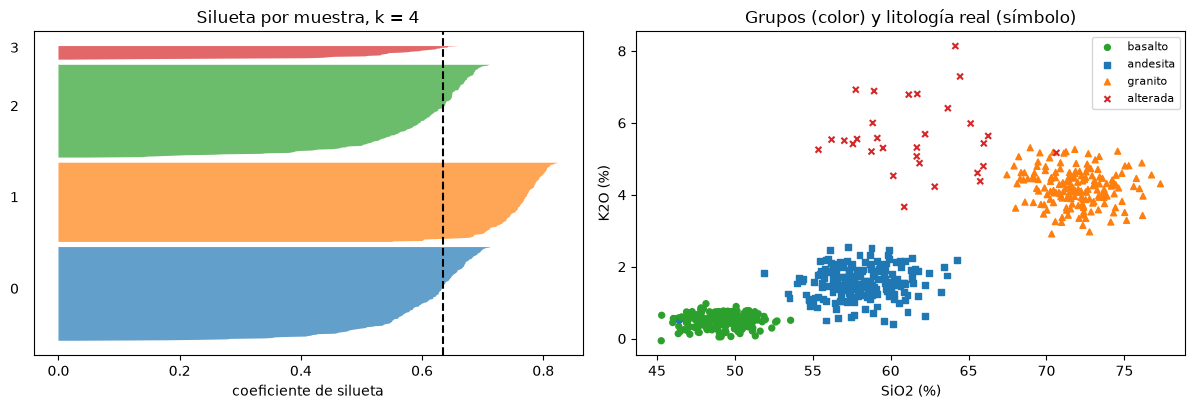

Índice de Rand ajustado frente a la litología real: k=3 0.924, k=4 0.995


In [3]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Xs)
km4 = KMeans(n_clusters=4, n_init=10, random_state=0).fit(Xs)
s = silhouette_samples(Xs, km4.labels_)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
y0 = 0
for g in range(4):
    v = np.sort(s[km4.labels_ == g]); ax[0].fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.7); ax[0].text(-0.08, y0 + len(v) / 2, str(g)); y0 += len(v) + 10
ax[0].axvline(s.mean(), color='k', ls='--'); ax[0].set_xlabel('coeficiente de silueta'); ax[0].set_title('Silueta por muestra, k = 4'); ax[0].set_yticks([])
for nom, mk in zip(medias, ['o', 's', '^', 'x']):
    m = lito == nom
    ax[1].scatter(X[m, 0], X[m, 4], c=km4.labels_[m], cmap='tab10', vmin=0, vmax=9, marker=mk, s=18, label=nom)
ax[1].set_xlabel('SiO2 (%)'); ax[1].set_ylabel('K2O (%)'); ax[1].legend(fontsize=8); ax[1].set_title('Grupos (color) y litología real (símbolo)')
plt.tight_layout(); plt.show()
print(f'Índice de Rand ajustado frente a la litología real: k=3 {adjusted_rand_score(lito, km3.labels_):.3f}, k=4 {adjusted_rand_score(lito, km4.labels_):.3f}')

## Agrupamiento jerárquico

El agrupamiento jerárquico aglomerativo empieza con cada observación como un grupo y une en cada paso los dos grupos más parecidos, hasta formar uno solo. El resultado es un dendrograma, que muestra toda la jerarquía y permite elegir el número de grupos cortándolo a una altura. La similitud entre grupos se define con un criterio de enlace: el sencillo (distancia mínima) tiende a formar cadenas; el completo (distancia máxima) forma grupos compactos; el promedio es intermedio; y el de Ward une los grupos que menos aumentan la varianza interna, y suele dar los resultados más parecidos a k-medias. El coeficiente de correlación cofenética mide qué tan bien conserva el dendrograma las distancias originales; cuanto más cercano a 1, mejor.

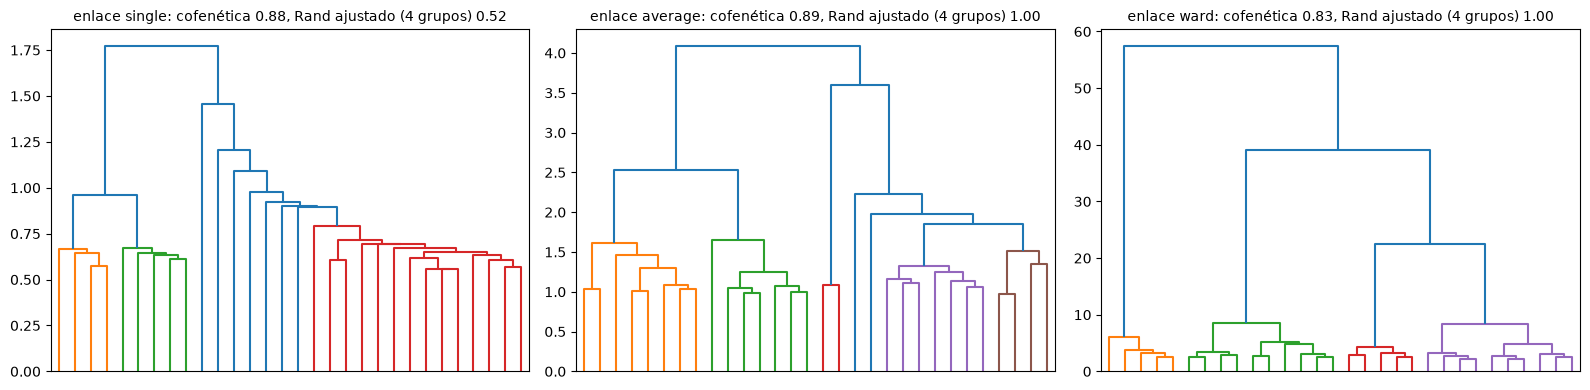

In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
d = pdist(Xs)
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, met in zip(axs, ['single', 'average', 'ward']):
    Z = linkage(Xs, met)
    c, _ = cophenet(Z, d)
    dendrogram(Z, ax=ax, truncate_mode='lastp', p=30, no_labels=True, color_threshold=0.7 * Z[-3, 2])
    ari = adjusted_rand_score(lito, fcluster(Z, 4, 'maxclust'))
    ax.set_title(f'enlace {met}: cofenética {c:.2f}, Rand ajustado (4 grupos) {ari:.2f}', fontsize=10)
plt.tight_layout(); plt.show()

## DBSCAN: grupos por densidad

DBSCAN {cite}`ester1996` define los grupos como regiones densas separadas por regiones vacías. Un punto es núcleo si tiene al menos `min_samples` vecinos a una distancia menor que `eps`; los grupos se forman encadenando núcleos vecinos, y los puntos que no alcanzan ningún núcleo se marcan como ruido. No exige fijar el número de grupos, encuentra grupos de cualquier forma y detecta atípicos, pero es sensible a `eps` y funciona mal si los grupos tienen densidades muy distintas. Es muy útil con datos espaciales, por ejemplo para encontrar enjambres de sismos o concentraciones de deslizamientos. La celda siguiente lo compara con k-medias en un caso con grupos alargados y ruido.

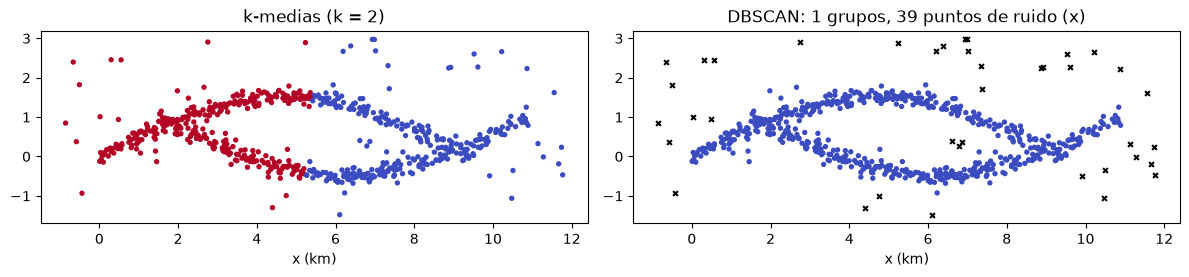

In [5]:
from sklearn.cluster import DBSCAN
t = rng.uniform(0, np.pi, 300)
falla1 = np.column_stack([t * 3, 1.5 * np.sin(t) + rng.normal(0, 0.12, 300)])
falla2 = np.column_stack([t * 3 + 1.5, -1.5 * np.sin(t) + 1 + rng.normal(0, 0.12, 300)])
fondo = rng.uniform([-1, -1.5], [12, 3], (60, 2))
P = np.vstack([falla1, falla2, fondo])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(*P.T, c=KMeans(2, n_init=10, random_state=0).fit_predict(P), cmap='coolwarm', s=8); ax[0].set_title('k-medias (k = 2)')
lab = DBSCAN(eps=0.45, min_samples=6).fit_predict(P)
ax[1].scatter(*P[lab >= 0].T, c=lab[lab >= 0], cmap='coolwarm', s=8); ax[1].scatter(*P[lab < 0].T, c='k', marker='x', s=12)
ax[1].set_title(f'DBSCAN: {lab.max() + 1} grupos, {np.sum(lab < 0)} puntos de ruido (x)')
for a in ax: a.set_aspect('equal'); a.set_xlabel('x (km)')
plt.tight_layout(); plt.show()

## Para profundizar

La sección 12.4 de {cite}`james2021` presenta k-medias y el agrupamiento jerárquico, y el capítulo 14 de {cite}`hastie2009` cubre más métodos. El notebook 12 del curso aplica el agrupamiento a datos tabulares y a una imagen de satélite, con análisis de silueta y de cardinalidad y magnitud de los grupos.